# drop linear column in AE data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('AE.csv')
df.head()

,Time,Absolute_Energy,Amplitude,ASL,Average_Frequency,Channel,Counts,Counts_to_Peak,Duration,Energy,...,Partial_Power_1,Partial_Power_2,Partial_Power_3,Partial_Power_4,Peak_Frequency,Reverberation_Frequency,Risetime,RMS,Signal_Strength,Threshold
0,66.077003,5425.141100,59,23,38,1,102,20,2713,38,...,100,0,0,0,19,33,277,0.015259,243130.7500,40
1,66.077187,153.299560,42,14,8,2,3,1,376,2,...,92,6,1,0,19,5,4,0.003052,15530.6000,40
2,66.140120,52.861664,40,26,0,1,1,1,2713,38,...,99,0,0,0,19,0,277,0.021363,243130.7500,40
3,66.269504,71.661064,41,27,42,1,2,1,48,0,...,100,0,0,0,19,35,19,0.024415,1967.2500,40
4,66.333303,87.173759,40,27,10,1,2,2,191,1,...,99,0,0,0,19,0,191,0.024415,6752.7002,40


In [3]:
df.corr()

,Time,Absolute_Energy,Amplitude,ASL,Average_Frequency,Channel,Counts,Counts_to_Peak,Duration,Energy,...,Partial_Power_1,Partial_Power_2,Partial_Power_3,Partial_Power_4,Peak_Frequency,Reverberation_Frequency,Risetime,RMS,Signal_Strength,Threshold
Time,1.000000,-0.002948,-0.007270,0.008003,0.025787,0.114810,0.246070,0.325164,0.188125,0.144187,...,0.079214,0.002370,-0.116357,-0.006022,0.158102,0.087727,0.279031,-0.000452,0.143875,NaN
Absolute_Energy,-0.002948,1.000000,0.301800,0.114541,-0.036472,-0.085095,0.347383,0.143574,0.221197,0.454244,...,0.035542,-0.034404,-0.006895,-0.003191,-0.027883,0.196782,0.134348,0.142439,0.453741,NaN
Amplitude,-0.007270,0.301800,1.000000,0.444358,-0.247703,-0.426926,0.859879,0.629995,0.837323,0.883004,...,0.171087,-0.147972,-0.043823,-0.013604,-0.144893,0.619800,0.616581,0.427016,0.883763,NaN
ASL,0.008003,0.114541,0.444358,1.000000,-0.130483,-0.920677,0.449103,0.388744,0.462558,0.445466,...,0.369395,-0.446072,-0.111103,-0.026381,-0.325254,0.386010,0.398478,0.948727,0.445945,NaN
Average_Frequency,0.025787,-0.036472,-0.247703,-0.130483,1.000000,0.131691,-0.190873,-0.165144,-0.230423,-0.199358,...,-0.067688,0.050227,0.018796,-0.008080,0.048645,-0.276063,-0.192516,-0.120681,-0.202250,NaN
Channel,0.114810,-0.085095,-0.426926,-0.920677,0.131691,1.000000,-0.421506,-0.371102,-0.441047,-0.410341,...,-0.378278,0.468661,0.101627,0.027784,0.354209,-0.384160,-0.380074,-0.826430,-0.410883,NaN
Counts,0.246070,0.347383,0.859879,0.449103,-0.190873,-0.421506,1.000000,0.818338,0.928024,0.950306,...,0.202639,-0.178617,-0.072356,-0.014301,-0.124134,0.603365,0.772509,0.429910,0.950375,NaN
Counts_to_Peak,0.325164,0.143574,0.629995,0.388744,-0.165144,-0.371102,0.818338,1.000000,0.795553,0.743029,...,0.202244,-0.174844,-0.087424,-0.015747,-0.113201,0.442624,0.933911,0.361724,0.743222,NaN
Duration,0.188125,0.221197,0.837323,0.462558,-0.230423,-0.441047,0.928024,0.795553,1.000000,0.939195,...,0.220049,-0.193974,-0.084073,-0.009979,-0.154577,0.514488,0.834129,0.435734,0.939601,NaN
Energy,0.144187,0.454244,0.883004,0.445466,-0.199358,-0.410341,0.950306,0.743029,0.939195,1.000000,...,0.199333,-0.177673,-0.073081,-0.010979,-0.144828,0.540844,0.752723,0.434031,0.999956,NaN


<Axes: >

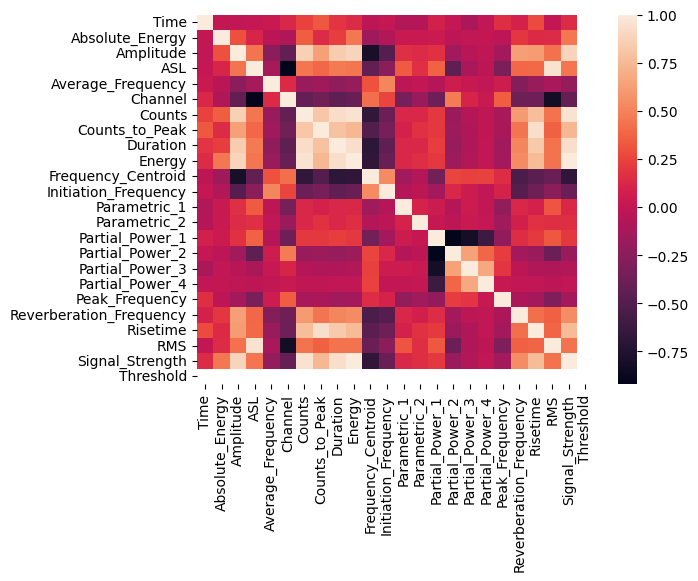

In [4]:
sns.heatmap(df.corr())

In [5]:
def remove_highly_correlated_features(df, threshold=0.75):
    # 1. 计算绝对值相关系数矩阵
    corr_matrix = df.corr().abs()
    
    # 2. 提取上三角矩阵（不包括对角线）
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # 3. 找出相关系数超过阈值的列
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    
    # 4. 删除这些列
    return df.drop(columns=to_drop)

In [6]:
df = remove_highly_correlated_features(df)
df.head()

,Time,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Partial_Power_1,Partial_Power_4,Peak_Frequency,Reverberation_Frequency,Threshold
0,66.077003,5425.141100,59,23,38,72,0.033570,0.475478,100,0,19,33,40
1,66.077187,153.299560,42,14,8,250,0.032960,0.451369,92,0,19,5,40
2,66.140120,52.861664,40,26,0,3,0.036012,0.647603,99,0,19,0,40
3,66.269504,71.661064,41,27,42,52,0.036317,0.581988,100,0,19,35,40
4,66.333303,87.173759,40,27,10,10,0.036317,0.643941,99,0,19,0,40


In [7]:
df.corr()

,Time,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Partial_Power_1,Partial_Power_4,Peak_Frequency,Reverberation_Frequency,Threshold
Time,1.000000,-0.002948,-0.007270,0.008003,0.025787,0.008727,-0.073677,-0.064169,0.079214,-0.006022,0.158102,0.087727,NaN
Absolute_Energy,-0.002948,1.000000,0.301800,0.114541,-0.036472,-0.079752,0.027241,0.027522,0.035542,-0.003191,-0.027883,0.196782,NaN
Amplitude,-0.007270,0.301800,1.000000,0.444358,-0.247703,-0.488872,0.165094,0.139502,0.171087,-0.013604,-0.144893,0.619800,NaN
ASL,0.008003,0.114541,0.444358,1.000000,-0.130483,-0.259049,0.338029,0.163691,0.369395,-0.026381,-0.325254,0.386010,NaN
Average_Frequency,0.025787,-0.036472,-0.247703,-0.130483,1.000000,0.515754,-0.021033,-0.006863,-0.067688,-0.008080,0.048645,-0.276063,NaN
Initiation_Frequency,0.008727,-0.079752,-0.488872,-0.259049,0.515754,1.000000,-0.069163,-0.025636,-0.138203,-0.006383,0.095065,-0.491526,NaN
Parametric_1,-0.073677,0.027241,0.165094,0.338029,-0.021033,-0.069163,1.000000,0.099621,0.043725,-0.002621,-0.208557,0.117644,NaN
Parametric_2,-0.064169,0.027522,0.139502,0.163691,-0.006863,-0.025636,0.099621,1.000000,0.016128,0.010737,-0.155047,0.076080,NaN
Partial_Power_1,0.079214,0.035542,0.171087,0.369395,-0.067688,-0.138203,0.043725,0.016128,1.000000,-0.611079,-0.217885,0.149297,NaN
Partial_Power_4,-0.006022,-0.003191,-0.013604,-0.026381,-0.008080,-0.006383,-0.002621,0.010737,-0.611079,1.000000,0.022811,-0.011133,NaN


<Axes: >

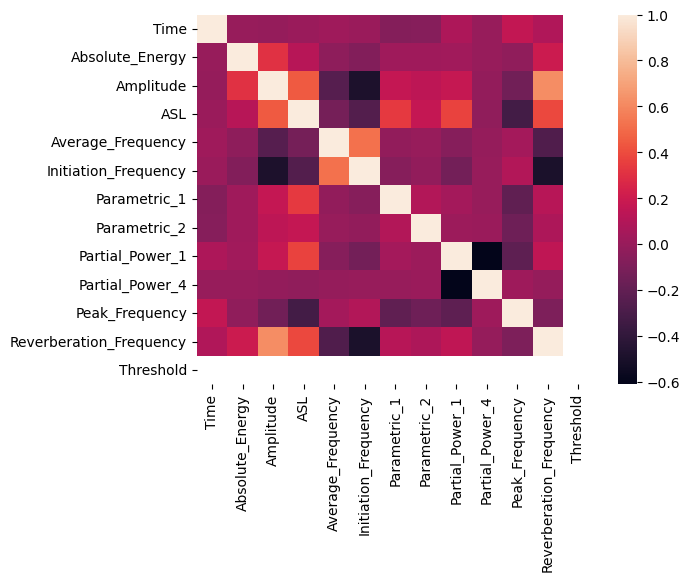

In [8]:
sns.heatmap(df.corr())

In [9]:
df_ae = df.drop(columns=['Partial_Power_1', 'Partial_Power_4'])
df_ae.head()

,Time,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold
0,66.077003,5425.141100,59,23,38,72,0.033570,0.475478,19,33,40
1,66.077187,153.299560,42,14,8,250,0.032960,0.451369,19,5,40
2,66.140120,52.861664,40,26,0,3,0.036012,0.647603,19,0,40
3,66.269504,71.661064,41,27,42,52,0.036317,0.581988,19,35,40
4,66.333303,87.173759,40,27,10,10,0.036317,0.643941,19,0,40


In [10]:
df_ae.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26493 entries, 0 to 26492
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Time                     26493 non-null  float64
 1   Absolute_Energy          26493 non-null  float64
 2   Amplitude                26493 non-null  int64  
 3   ASL                      26493 non-null  int64  
 4   Average_Frequency        26493 non-null  int64  
 5   Initiation_Frequency     26493 non-null  int64  
 6   Parametric_1             26493 non-null  float64
 7   Parametric_2             26493 non-null  float64
 8   Peak_Frequency           26493 non-null  int64  
 9   Reverberation_Frequency  26493 non-null  int64  
 10  Threshold                26493 non-null  int64  
dtypes: float64(4), int64(7)
memory usage: 2.2 MB


In [11]:
df_friction = pd.read_csv('friction.csv')
df_friction.head()

,Time,F_in,F_out,Displacement,coe
0,0.00,-0.09159,0.08956,-0.09159,0.017912
1,0.02,-0.08640,-0.16925,-0.08640,-0.033850
2,0.04,-0.04043,-0.15737,-0.04043,-0.031474
3,0.06,-0.04970,-0.07228,-0.04970,-0.014456
4,0.08,-0.05174,0.07132,-0.05174,0.014264


In [12]:
df_friction = df_friction.drop(columns=['F_in', 'F_out', 'Displacement'])
df_friction['Time'] = df_friction['Time'].round(2)
df_friction.head()

,Time,coe
0,0.00,0.017912
1,0.02,-0.033850
2,0.04,-0.031474
3,0.06,-0.014456
4,0.08,0.014264


In [13]:
df_friction.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9947 entries, 0 to 9946
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    9947 non-null   float64
 1   coe     9947 non-null   float64
dtypes: float64(2)
memory usage: 155.6 KB


# replace timestamp with the number of cycles

In [14]:
def timestamp_to_cycles(df, col_name, frequency, df2 = pd.DataFrame()):
    '''
    df: the dateframe that we want to preprocess
    col_name: the name of timestamp column
    frequency: the frequency of the experiment
    df2: a void dateframe that we will use to storage the processed dataframe
    
    '''
    df['cycle'] = np.floor(df[col_name] * frequency)+1
    df2 = df.groupby('cycle').apply(lambda x: x.abs().mean(), include_groups=False).reset_index()  # use the mean absolute value to represent the feature in this cycle
    df2 = df2.drop(columns = [col_name])
    return df2


In [15]:
df_ae_processed = timestamp_to_cycles(df_ae, 'Time', 5)
df_ae_processed.head()

,cycle,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold
0,331.0,1877.100775,47.000000,21.000000,15.333333,108.333333,0.034181,0.524817,19.000000,12.666667,40.0
1,332.0,85.861459,41.000000,27.000000,272.000000,274.750000,0.036317,0.577868,19.000000,18.000000,40.0
2,333.0,2699.049596,46.923077,30.615385,176.000000,339.307692,0.021152,0.495597,19.000000,15.846154,40.0
3,334.0,4307.793999,46.727273,31.363636,69.454545,304.272727,0.024775,0.576356,36.272727,21.363636,40.0
4,335.0,687.459703,44.411765,33.705882,77.000000,317.058824,0.023786,0.542458,25.882353,13.117647,40.0


In [16]:
df_friction_processed = timestamp_to_cycles(df_friction, 'Time', 5)
df_friction_processed.head()

,cycle,coe
0,1.0,0.021518
1,2.0,0.009959
2,3.0,0.021819
3,4.0,0.019355
4,5.0,0.012795


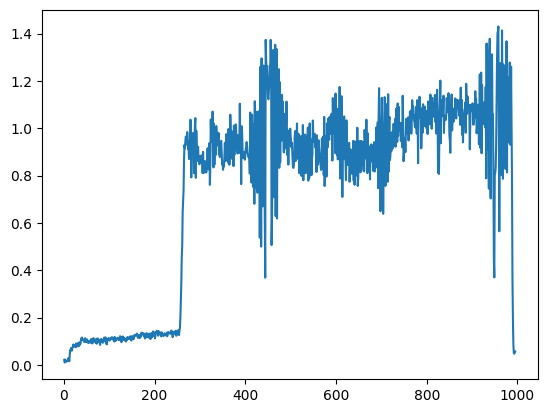

In [17]:
plt.plot(df_friction_processed['cycle'], df_friction_processed['coe'])

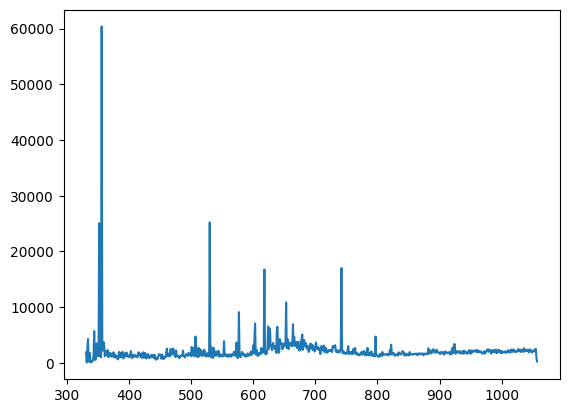

In [18]:
plt.plot(df_ae_processed['cycle'], df_ae_processed['Absolute_Energy'])

# merge dataframe

In [19]:
df_prepared = pd.merge(df_friction_processed, df_ae_processed, on = 'cycle', how = 'outer')

In [20]:
df_prepared.head()

,cycle,coe,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold
0,1.0,0.021518,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,0.009959,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3.0,0.021819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4.0,0.019355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5.0,0.012795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
df_prepared = df_prepared.dropna(subset = ['coe'])
df_prepared.tail()

,cycle,coe,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold
990,991.0,0.086929,2391.906373,46.965517,36.137931,111.172414,144.241379,0.016333,0.890435,21.758621,18.827586,40.0
991,992.0,0.049741,1768.682386,45.725000,35.750000,38.275000,243.725000,0.017464,0.888943,22.500000,14.975000,40.0
992,993.0,0.047249,1797.318103,45.631579,35.868421,59.815789,153.552632,0.019098,0.892442,22.289474,16.000000,40.0
993,994.0,0.051125,2271.331212,46.281250,35.750000,33.718750,173.437500,0.016404,0.901584,25.062500,15.125000,40.0
994,995.0,0.056507,1959.186301,45.972222,35.500000,43.750000,273.833333,0.015675,0.909197,24.000000,15.083333,40.0


# label

In [22]:
def get_label(x):
    if x <= 330:
        return 'stage1'
    elif x <= 475:
        return 'stage2'
    elif x <= 550:
        return 'stage3'
    else:
        return 'stage4'

df_prepared['stage'] = df_prepared['cycle'].apply(get_label)
df_prepared.head()

,cycle,coe,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold,stage
0,1.0,0.021518,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
1,2.0,0.009959,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
2,3.0,0.021819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
3,4.0,0.019355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
4,5.0,0.012795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1


In [23]:
df_prepared.tail()

,cycle,coe,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold,stage
990,991.0,0.086929,2391.906373,46.965517,36.137931,111.172414,144.241379,0.016333,0.890435,21.758621,18.827586,40.0,stage4
991,992.0,0.049741,1768.682386,45.725000,35.750000,38.275000,243.725000,0.017464,0.888943,22.500000,14.975000,40.0,stage4
992,993.0,0.047249,1797.318103,45.631579,35.868421,59.815789,153.552632,0.019098,0.892442,22.289474,16.000000,40.0,stage4
993,994.0,0.051125,2271.331212,46.281250,35.750000,33.718750,173.437500,0.016404,0.901584,25.062500,15.125000,40.0,stage4
994,995.0,0.056507,1959.186301,45.972222,35.500000,43.750000,273.833333,0.015675,0.909197,24.000000,15.083333,40.0,stage4


# add experimental information

In [24]:
# add other info

df_prepared.insert(0, 'material', 'steel-glass') # add a column of experiment material
df_prepared.insert(1, 'stroke', 100) # add a column of stroke distance
df_prepared.insert(2, 'osc_freq', 5) # add a column of the oscillation frequency
df_prepared.insert(3, 'force', 5) # add a column of the normal force
df_prepared.head()



,material,stroke,osc_freq,force,cycle,coe,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold,stage
0,steel-glass,100,5,5,1.0,0.021518,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
1,steel-glass,100,5,5,2.0,0.009959,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
2,steel-glass,100,5,5,3.0,0.021819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
3,steel-glass,100,5,5,4.0,0.019355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1
4,steel-glass,100,5,5,5.0,0.012795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,stage1


In [25]:
df_prepared.fillna(0, inplace=True)

In [26]:
df_prepared.to_csv('processed_data.csv')